# 第 1 天：AOI 基础与质量指标

**目标**：用 Python 算出混淆矩阵和质量指标，并能解释为什么"准确率高"不等于"检测系统可靠"。

判断口径固定为：**正类 = 真实有缺陷**。

| | 实际有缺陷 | 实际无缺陷 |
| --- | ---: | ---: |
| 模型判定有缺陷 | TP：正确检出 | FP：误报 |
| 模型判定无缺陷 | FN：漏检 | TN：正确放行 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
)

sns.set_theme(style="whitegrid")


def quality_metrics(tn, fp, fn, tp):
    def ratio(a, b):
        return a / b if b else np.nan

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": ratio(tp, tp + fp),
        "Recall": ratio(tp, tp + fn),
        "FPR": ratio(fp, fp + tn),
        "Miss rate": ratio(fn, tp + fn),
        "Accuracy": ratio(tp + tn, tp + tn + fp + fn),
        "Manual review (all alarms)": tp + fp,
    }

## 1. 讲义里的练习：10,000 件产品，100 件真实缺陷

- AOI 检出真实缺陷 95 件，漏检 5 件
- AOI 把 495 件良品误报为不良，其余 9,405 件良品正确放行

In [2]:
y_true = [1] * 100 + [0] * 9900
y_pred = [1] * 95 + [0] * 5 + [1] * 495 + [0] * 9405

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print(f"TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")
print(f"Precision: {precision_score(y_true, y_pred):.2%}")
print(f"Recall: {recall_score(y_true, y_pred):.2%}")
print(f"False positive rate: {fp / (fp + tn):.2%}")
print(f"Miss rate: {fn / (fn + tp):.2%}")
print(f"Manual review (all alarms): {tp + fp}")

TP: 95, FP: 495, FN: 5, TN: 9405
Precision: 16.10%
Recall: 95.00%
False positive rate: 5.00%
Miss rate: 5.00%
Manual review (all alarms): 590


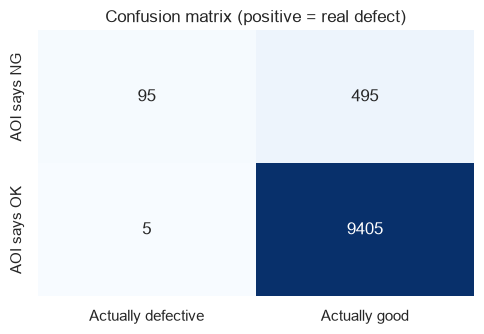

In [3]:
cm = pd.DataFrame(
    [[tp, fp], [fn, tn]],
    index=["AOI says NG", "AOI says OK"],
    columns=["Actually defective", "Actually good"],
)
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Confusion matrix (positive = real defect)")
plt.tight_layout()

对照讲义答案做断言：数字对不上就会直接报错。

In [4]:
m = quality_metrics(tn, fp, fn, tp)
assert np.isclose(m["Recall"], 0.95)
assert np.isclose(m["Precision"], 95 / 590)
assert np.isclose(m["FPR"], 0.05)
assert np.isclose(m["Miss rate"], 0.05)
assert m["Manual review (all alarms)"] == 590
assert np.isclose(m["Accuracy"], accuracy_score(y_true, y_pred))
print("全部与讲义答案一致")

全部与讲义答案一致


## 2. 为什么不能只看准确率

缺陷只占 1%。一台"什么都判良品"的设备，准确率反而比这台 AOI 更高。

In [5]:
scenarios = {
    "AOI (as above)": (tn, fp, fn, tp),
    "Predict everything OK": (9900, 0, 100, 0),
    "Predict everything NG": (0, 9900, 0, 100),
}
compare = pd.DataFrame({name: quality_metrics(*cells) for name, cells in scenarios.items()}).T
compare[["TP", "FP", "FN", "TN", "Manual review (all alarms)"]] = compare[
    ["TP", "FP", "FN", "TN", "Manual review (all alarms)"]
].astype(int)
compare.style.format(
    {c: "{:.2%}" for c in ["Precision", "Recall", "FPR", "Miss rate", "Accuracy"]},
    na_rep="undefined",
)

,TP,FP,FN,TN,Precision,Recall,FPR,Miss rate,Accuracy,Manual review (all alarms)
AOI (as above),95,495,5,9405,16.10%,95.00%,5.00%,5.00%,95.00%,590
Predict everything OK,0,0,100,9900,undefined,0.00%,0.00%,100.00%,99.00%,0
Predict everything NG,100,9900,0,0,1.00%,100.00%,100.00%,0.00%,1.00%,10000


"全判良品"的准确率 99%，但召回率 0%，漏掉所有缺陷。**准确率会被占绝对多数的良品"稀释"**，
所以评价 AOI 必须同时看 Recall、漏检数量、误报数量，并按缺陷类型拆开看。

## 3. "误报率"到底除以谁：口径陷阱

同样是 495 个误报，换一个分母，数字完全不同。回答前一定先确认分母和统计单位。

In [6]:
total = tn + fp + fn + tp
display(
    pd.DataFrame(
        {
            "Name": [
                "FPR（良品误报率）",
                "报警中的误报占比（1 - Precision）",
                "误报占全部检测数",
            ],
            "Formula": ["FP / (FP + TN)", "FP / (TP + FP)", "FP / Total"],
            "Value": [fp / (fp + tn), fp / (tp + fp), fp / total],
        }
    ).style.format({"Value": "{:.2%}"})
)

,Name,Formula,Value
0,FPR（良品误报率）,FP / (FP + TN),5.00%
1,报警中的误报占比（1 - Precision）,FP / (TP + FP),83.90%
2,误报占全部检测数,FP / Total,4.95%


- 良品误报率只有 5%，但**人工看到的报警里 84% 是误报**，这才是现场感受到的痛点。
- 现场说"误报率"时，可能指的是后者；对方说的是哪个，先问清楚。

## 4. 缺陷率对 Precision 的影响

假设设备能力不变（Recall 95%，FPR 5%），只改变缺陷率：

,Defect rate,Precision
0,0.1%,1.9%
1,0.5%,8.7%
2,1.0%,16.1%
3,2.0%,27.9%
4,5.0%,50.0%
5,10.0%,67.9%


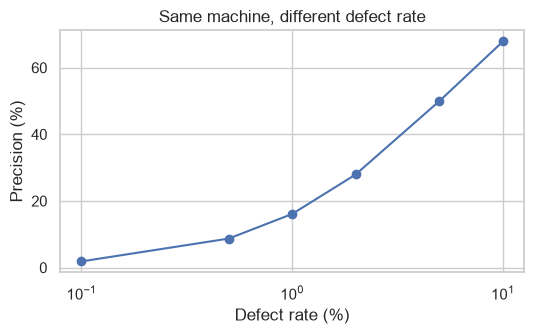

In [7]:
recall_fixed, fpr_fixed = 0.95, 0.05
defect_rates = np.array([0.001, 0.005, 0.01, 0.02, 0.05, 0.10])
precision_by_rate = (recall_fixed * defect_rates) / (
    recall_fixed * defect_rates + fpr_fixed * (1 - defect_rates)
)

display(
    pd.DataFrame({"Defect rate": defect_rates, "Precision": precision_by_rate}).style.format(
        {"Defect rate": "{:.1%}", "Precision": "{:.1%}"}
    )
)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(defect_rates * 100, precision_by_rate * 100, marker="o")
ax.set_xscale("log")
ax.set_xlabel("Defect rate (%)")
ax.set_ylabel("Precision (%)")
ax.set_title("Same machine, different defect rate")
plt.tight_layout()

缺陷越稀少，同一台设备的 Precision 越低。**产线良率越高，"报警里大部分是误报"就越不可避免**，
这也是为什么要在 AOI 后面做复判，而不是一味调严阈值。

## 5. 本日小结

| 交付物 | 位置 |
| --- | --- |
| 混淆矩阵与指标计算 Notebook | 本文件 |
| 1 分钟口头解释：准确率高不代表可靠 | `reports/interview_notes.md` 第 1 节 |
| 误报增加时如何排查 | `reports/interview_notes.md` 第 2 节 |